Importing Libraries

In [6]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier



Dataset Overview

In [ ]:
# Load dataset
df = pd.read_csv('Crop_recommendation.csv')
print("Rows, columns:", df.shape)
print(df.head())
df.info()
print("Crops:", df["label"].nunique())

<class 'pandas.DataFrame'>
RangeIndex: 2200 entries, 0 to 2199
Data columns (total 8 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   N            2200 non-null   int64  
 1   P            2200 non-null   int64  
 2   K            2200 non-null   int64  
 3   temperature  2200 non-null   float64
 4   humidity     2200 non-null   float64
 5   ph           2200 non-null   float64
 6   rainfall     2200 non-null   float64
 7   label        2200 non-null   str    
dtypes: float64(4), int64(3), str(1)
memory usage: 137.6 KB


In [13]:
df.head()

,N,P,K,temperature,humidity,ph,rainfall,label
0,90,42,43,20.879744,82.002744,6.502985,202.935536,rice
1,85,58,41,21.770462,80.319644,7.038096,226.655537,rice
2,60,55,44,23.004459,82.320763,7.840207,263.964248,rice
3,74,35,40,26.491096,80.158363,6.980401,242.864034,rice
4,78,42,42,20.130175,81.604873,7.628473,262.717340,rice


Separating Numerical Columns

In [8]:
# Numerical columns
columns = ['N', 'P', 'K', 'temperature', 'humidity', 'ph', 'rainfall']

Identifying Outliers
1- Using Boxplot
2- Using Scatterplot
3- Using IQR method

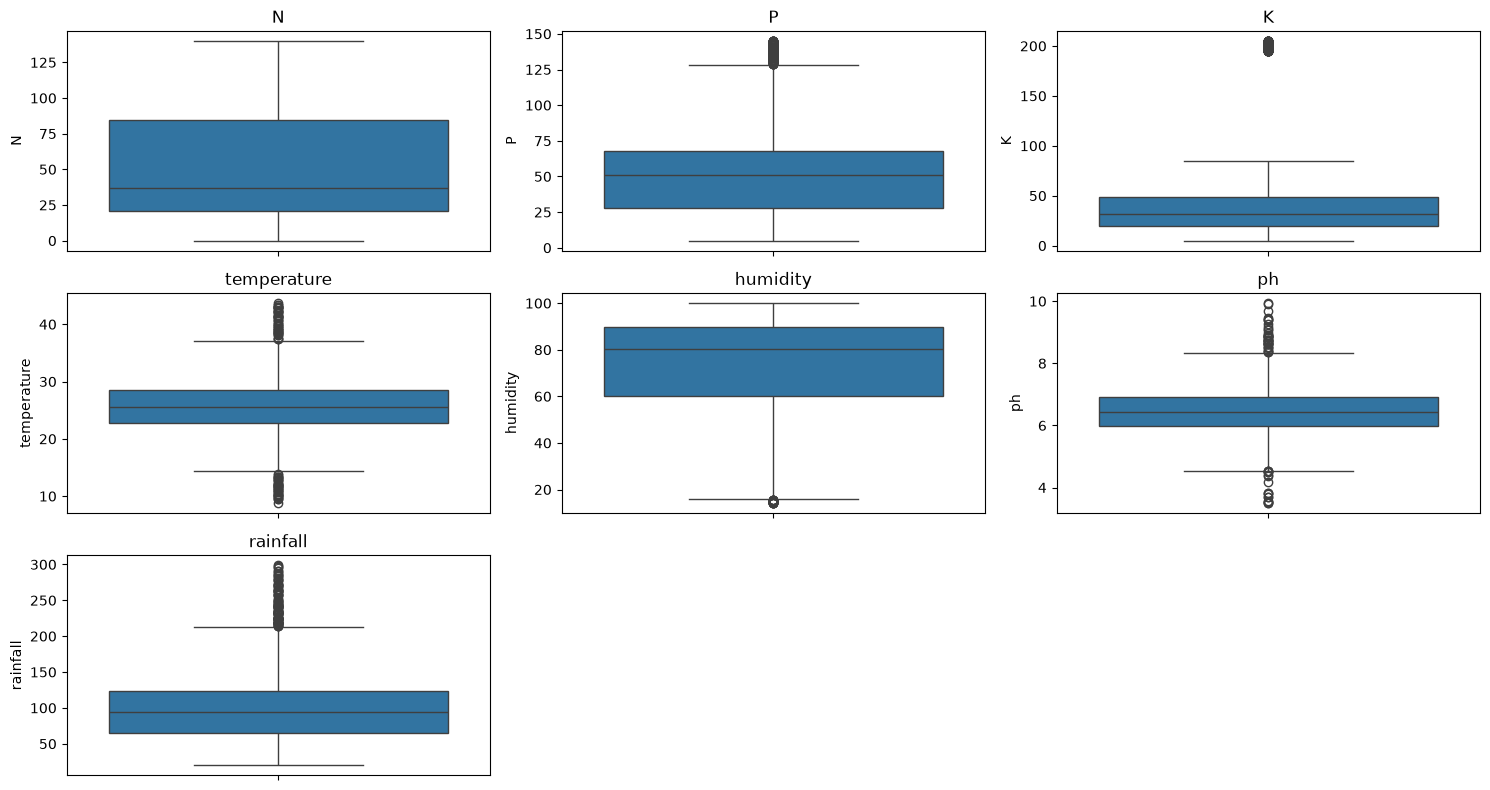

In [9]:
# 1. Boxplots
plt.figure(figsize=(15, 8))
for i, col in enumerate(columns):
    plt.subplot(3, 3, i+1)
    sns.boxplot(y=df[col])
    plt.title(col)
plt.tight_layout()
plt.show()

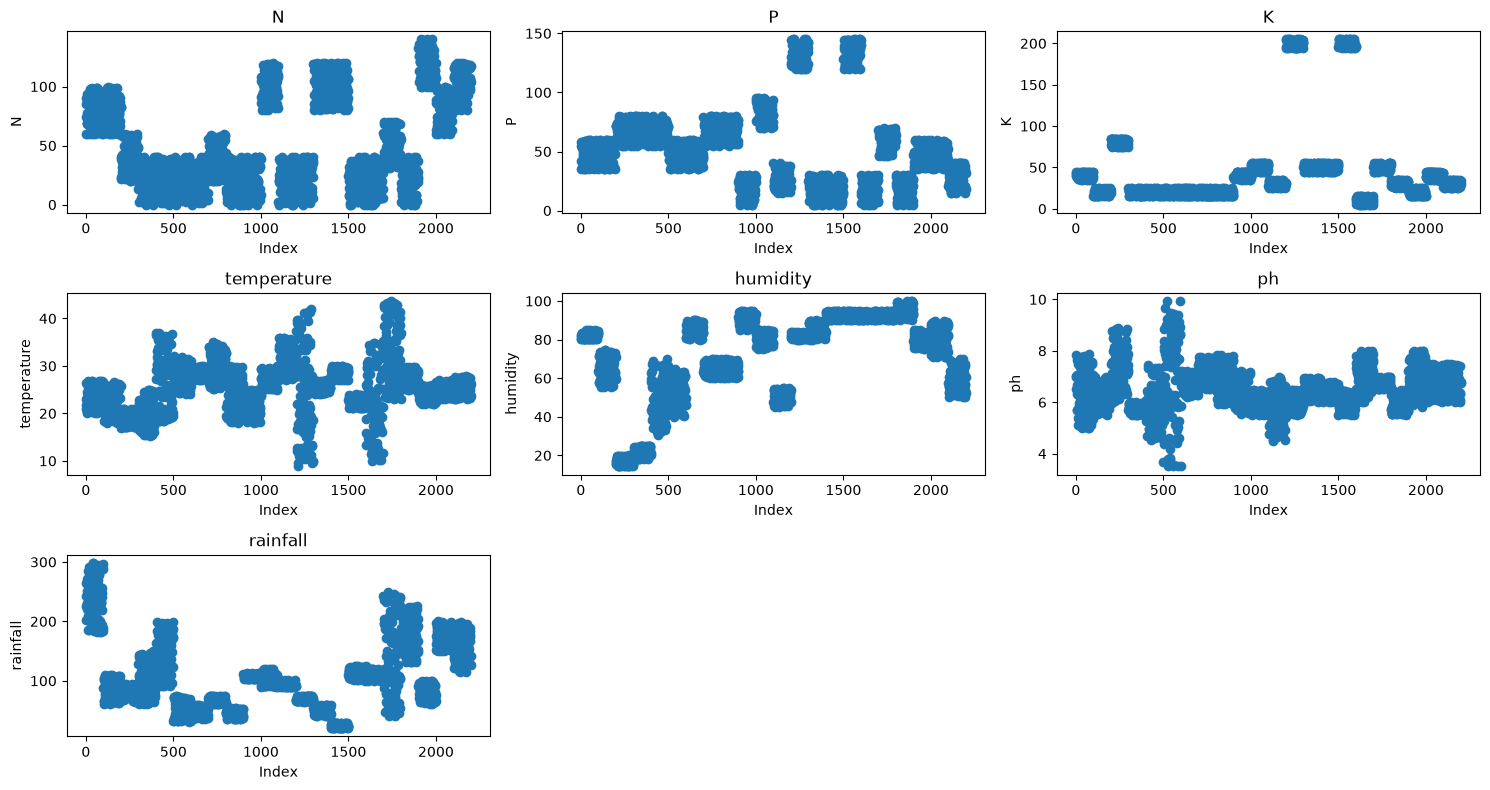

In [10]:
# 2. Scatter plots
plt.figure(figsize=(15, 8))
for i, col in enumerate(columns):
    plt.subplot(3, 3, i+1)
    plt.scatter(df.index, df[col])
    plt.title(col)
    plt.xlabel('Index')
    plt.ylabel(col)
plt.tight_layout()
plt.show()

In [11]:
# 3. IQR Method
for col in columns:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    outliers = df[(df[col] < lower) | (df[col] > upper)]

    print(f"{col}: {len(outliers)} outliers")

N: 0 outliers
P: 138 outliers
K: 200 outliers
temperature: 86 outliers
humidity: 30 outliers
ph: 57 outliers
rainfall: 100 outliers


Handling Outliers
1- Capping through IQR
2- Removal through Boxplot
3- Removal through z-score

In [14]:
# Created a separate copy
df_capped = df.copy()

columns = ['P', 'K', 'temperature', 'humidity', 'ph', 'rainfall']

for col in columns:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    df_capped[col] = df[col].clip(lower, upper)

print("Original Dataset:", df.shape)
print("Capped Dataset:", df_capped.shape)

Original Dataset: (2200, 8)
Capped Dataset: (2200, 8)


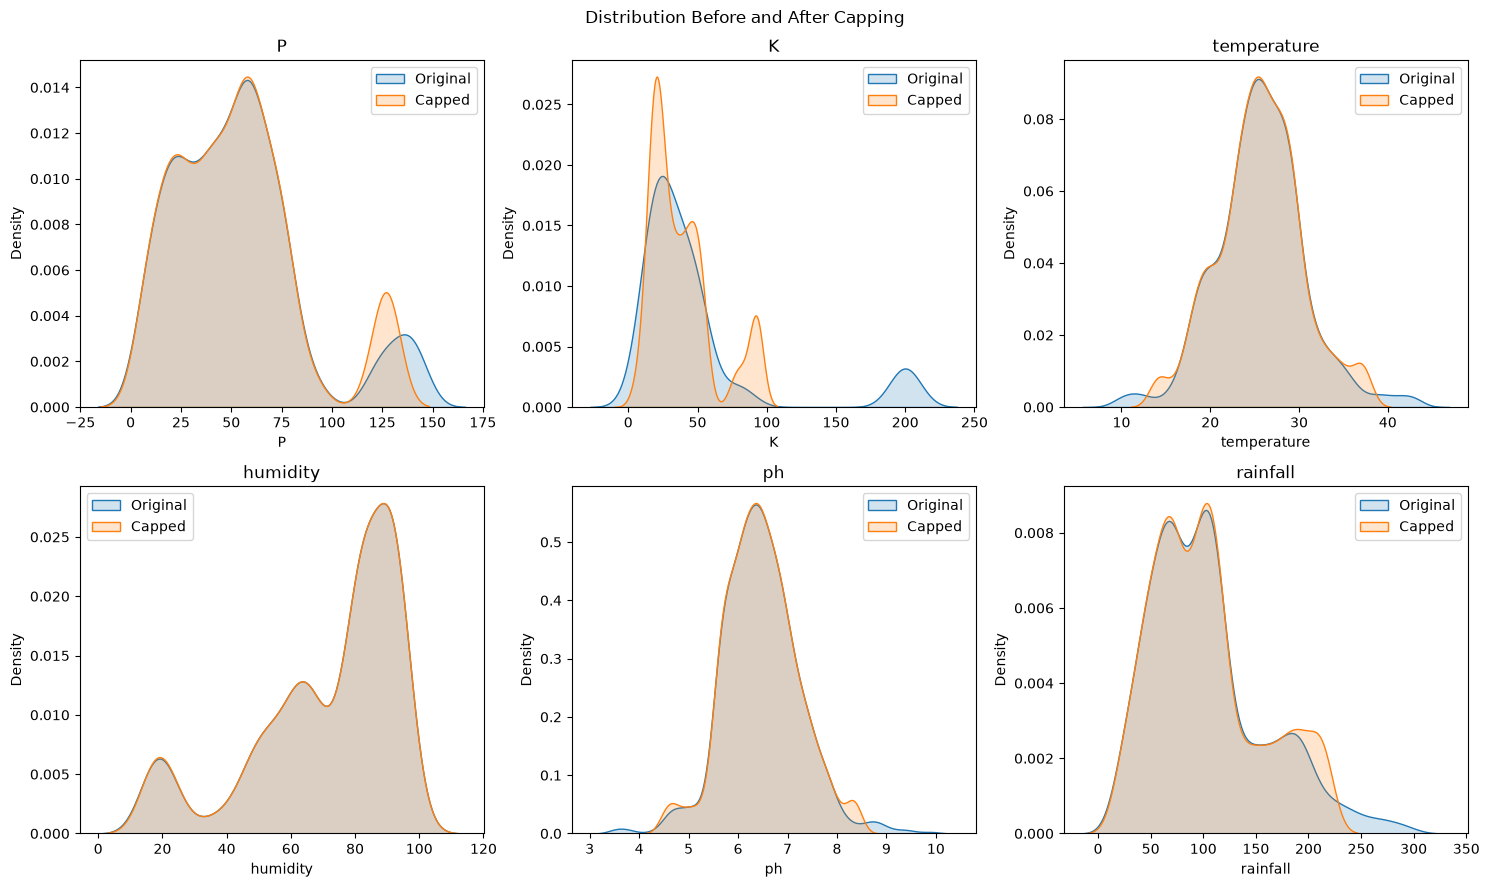

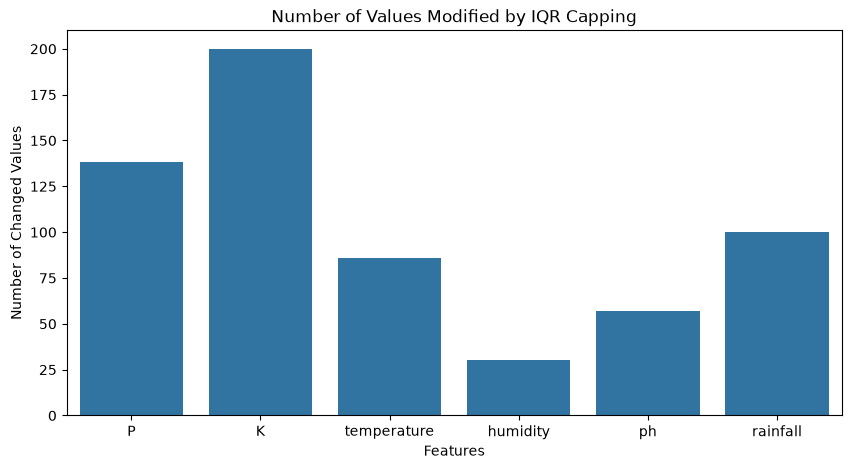

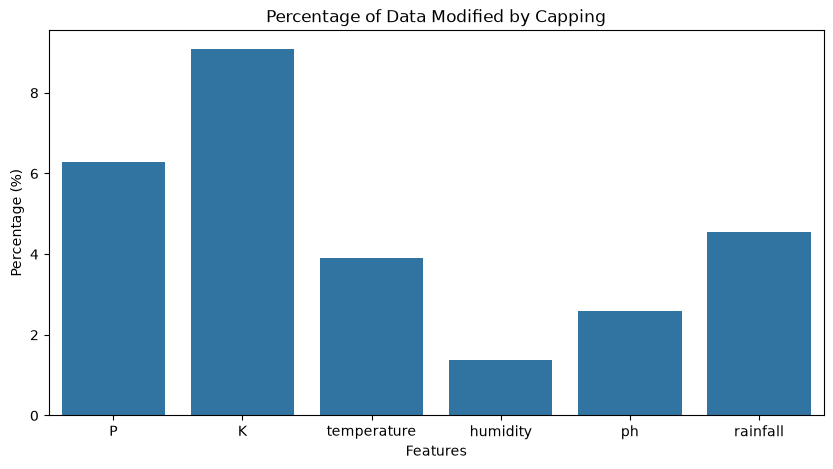

Values changed:
             Changed Values  Percentage
P                       138        6.27
K                       200        9.09
temperature              86        3.91
humidity                 30        1.36
ph                       57        2.59
rainfall                100        4.55


In [15]:

# Calculate how many values were changed
changed = (df[columns] != df_capped[columns]).sum()
percentage = (changed / len(df)) * 100

# 1. Before vs After Capping
fig, axes = plt.subplots(2, 3, figsize=(15, 9))

for i, col in enumerate(columns):
    sns.kdeplot(df[col], ax=axes[i//3, i%3],
                label='Original', fill=True, alpha=0.2)
    sns.kdeplot(df_capped[col], ax=axes[i//3, i%3],
                label='Capped', fill=True, alpha=0.2)
    axes[i//3, i%3].set_title(col)
    axes[i//3, i%3].legend()

plt.suptitle('Distribution Before and After Capping')
plt.tight_layout()
plt.show()


# 2. Number of Values Changed
plt.figure(figsize=(10, 5))
sns.barplot(x=changed.index, y=changed.values)
plt.title('Number of Values Modified by IQR Capping')
plt.ylabel('Number of Changed Values')
plt.xlabel('Features')
plt.show()


# 3. Percentage of Values Capped
plt.figure(figsize=(10, 5))
sns.barplot(x=percentage.index, y=percentage.values)
plt.title('Percentage of Data Modified by Capping')
plt.ylabel('Percentage (%)')
plt.xlabel('Features')
plt.show()

print("Values changed:")
print(pd.DataFrame({
    'Changed Values': changed,
    'Percentage': percentage.round(2)
}))

In [ ]:
      
features = ["N", "P", "K", "temperature", "humidity", "ph", "rainfall"]  

# ---------- Boxplot / IQR removal ----------
df_iqr = df.copy()
removed_per_feature_iqr = {}
mask_keep = pd.Series(True, index=df.index)

for col in features:
    Q1, Q3 = df[col].quantile([0.25, 0.75])
    IQR = Q3 - Q1
    lower, upper = Q1 - 1.5 * IQR, Q3 + 1.5 * IQR
    is_out = (df[col] < lower) | (df[col] > upper)
    removed_per_feature_iqr[col] = int(is_out.sum())
    mask_keep &= ~is_out

df_iqr = df[mask_keep].copy()

print("Outliers flagged per feature (IQR):")
print(pd.Series(removed_per_feature_iqr))
print(f"Rows before: {len(df)} | after: {len(df_iqr)} | removed: {len(df) - len(df_iqr)}")

# Boxplots before vs after
fig, axes = plt.subplots(2, len(features), figsize=(3*len(features), 7))
for i, col in enumerate(features):
    sns.boxplot(y=df[col], ax=axes[0, i], color="tomato");     axes[0, i].set_title(f"{col} (before)")
    sns.boxplot(y=df_iqr[col], ax=axes[1, i], color="seagreen"); axes[1, i].set_title(f"{col} (after)")
plt.tight_layout(); plt.show()


(2200, 8)
Original shape : (2200, 8)
After Z-score  : (2029, 8)
Rows removed   : 171
P               0
K              94
temperature    33
humidity        0
ph             30
rainfall       22
dtype: int64


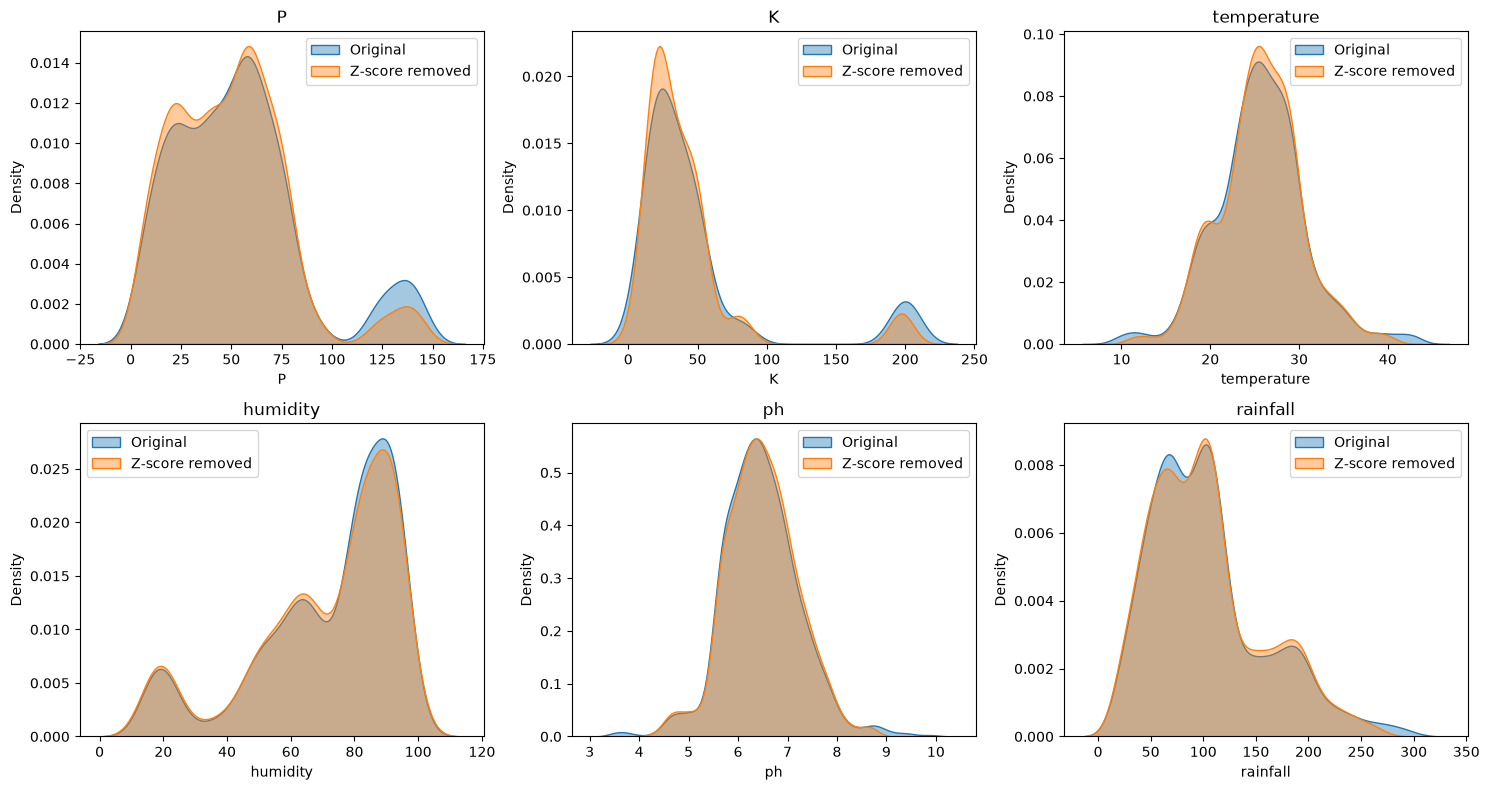

In [5]:


print(df.shape)

features = ['P', 'K', 'temperature', 'humidity', 'ph', 'rainfall']
df_zscore = df.copy()

# Z-scores for the six selected features
z_scores = np.abs(stats.zscore(df_zscore[features]))

# Keep only rows where every feature has |Z| <= 3
mask = (z_scores <= 3).all(axis=1)
df_zscore = df_zscore[mask].reset_index(drop=True)

print("Original shape :", df.shape)
print("After Z-score  :", df_zscore.shape)
print("Rows removed   :", df.shape[0] - df_zscore.shape[0])

z_all = np.abs(stats.zscore(df[features]))
outlier_counts = pd.Series((z_all > 3).sum(axis=0), index=features)
print(outlier_counts)


fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, col in zip(axes.flatten(), features):
    sns.kdeplot(df[col], ax=ax, label='Original', fill=True, alpha=0.4)
    sns.kdeplot(df_zscore[col], ax=ax, label='Z-score removed', fill=True, alpha=0.4)
    ax.set_title(col)
    ax.legend()
plt.tight_layout()
plt.show()


Adding Missing Values

In [ ]:
rng = np.random.default_rng(42)
d = df.copy()
for col in ["temperature", "humidity", "ph", "rainfall", "label"]:
    d.loc[rng.choice(d.index, 100, replace=False), col] = np.nan   # missing values
d = pd.concat([d, d.sample(30, random_state=1)], ignore_index=True)  # duplicates
i = rng.choice(d.index, 40, replace=False)
d.loc[i, "label"] = d.loc[i, "label"].str.upper()                   # CAPITAL letters
d.to_csv("crop_dirty.csv", index=False)
print("Dirty dataset shape:", d.shape)

In [ ]:
def show(name):                      # save the graph, then display it
    plt.tight_layout()
    plt.savefig(f"figures/{name}.png", dpi=110)
    plt.show()
d = pd.read_csv("crop_dirty.csv")
print(d.isnull().sum())
print("Duplicates:", d.duplicated().sum(), "| Unique labels:", d["label"].nunique())
sns.heatmap(d.isnull(), cbar=False, yticklabels=False)
plt.title("Missing values (light lines = missing)")
show("01_missing")
d["label"] = d["label"].str.lower().str.strip()
print("Duplicates after fixing letters:", d.duplicated().sum())
d = d.drop_duplicates()
print("Shape after cleaning:", d.shape, "| Unique labels:", d["label"].nunique())

Handling Missing Values through mode, mean and median Imputation

In [ ]:
d = pd.read_csv("crop_dirty.csv")
num = ["temperature", "humidity", "ph", "rainfall"]
mask = d[num].isnull()
def rmse(filled):                    # error only on the cells we deleted
    return pd.Series({c: np.sqrt(((filled.loc[mask[c], c] - df.loc[mask[c], c]) ** 2).mean())
                      for c in num}).round(2)
print("Missing numeric values:", int(mask.sum().sum()))

In [ ]:
# Step 1: Load datasets
df = pd.read_csv("Crop_recommendation.csv")
d = pd.read_csv("crop_dirty.csv")
# Step 2: Match original rows
d_original = d.iloc[:len(df)].copy()
# Step 3: Select numerical columns
num = ["temperature", "humidity", "ph", "rainfall"]
# Step 4: Identify missing values
mask = d_original[num].isnull()
print("Missing numeric values:", int(mask.sum().sum()))
# Step 5: Define RMSE function
def rmse(filled):
    return pd.Series({
        c: np.sqrt(
            ((filled.loc[mask[c], c] -
              df.loc[mask[c], c]) ** 2).mean()
        )
        for c in num
    }).round(2)
# Step 6: Create a copy
mean_df = d_original.copy()
# Step 7: Calculate Mean and fill missing values
mean_values = mean_df[num].mean()

mean_df[num] = mean_df[num].fillna(mean_values)
# Step 8: Display Mean values
print("\nValues used (Mean):")
print(mean_values.round(2))
# Step 9: Check remaining missing values
print("\nRemaining missing values:")
print(mean_df[num].isnull().sum())
# Step 10: Calculate RMSE
print("\nError (RMSE):")
print(rmse(mean_df))

In [ ]:
# Step 1: Load datasets
df = pd.read_csv("Crop_recommendation.csv")
d = pd.read_csv("crop_dirty.csv")
# Step 2: Match original rows
d_original = d.iloc[:len(df)].copy()
# Step 3: Select numerical columns
num = ["temperature", "humidity", "ph", "rainfall"]
# Step 4: Identify missing values
mask = d_original[num].isnull()
print("Missing numeric values:", int(mask.sum().sum()))
# Step 5: Define RMSE function
def rmse(filled):
    return pd.Series({
        c: np.sqrt(
            ((filled.loc[mask[c], c] -
              df.loc[mask[c], c]) ** 2).mean()
        )
        for c in num
    }).round(2)
# Step 6: Create a copy
median_df = d_original.copy()
# Step 7: Calculate Median and fill missing values
median_values = median_df[num].median()
median_df[num] = median_df[num].fillna(median_values)
# Step 8: Display Median values
print("\nValues used (Median):")
print(median_values.round(2))
# Step 9: Check remaining missing values
print("\nRemaining missing values:")
print(median_df[num].isnull().sum())
# Step 10: Calculate RMSE
print("\nError (RMSE):")
print(rmse(median_df))

In [ ]:
# Step 1: Load datasets
df = pd.read_csv("Crop_recommendation.csv")
d = pd.read_csv("crop_dirty.csv")
# Step 2: Match original rows
d_original = d.iloc[:len(df)].copy()
# Step 3: Select numerical columns
num = ["temperature", "humidity", "ph", "rainfall"]
# Step 4: Identify missing values
mask = d_original[num].isnull()
print("Missing numeric values:", int(mask.sum().sum()))
# Step 5: Define RMSE function
def rmse(filled):
    return pd.Series({
        c: np.sqrt(
            ((filled.loc[mask[c], c] -
              df.loc[mask[c], c]) ** 2).mean()
        )
        for c in num
    }).round(2)
# Step 6: Create a copy
mode_df = d_original.copy()
# Step 7: Calculate Mode
mode_values = mode_df[num].mode().iloc[0]
# Step 8: Fill missing values using Mode
mode_df[num] = mode_df[num].fillna(mode_values)
# Step 9: Display Mode values
print("\nValues used (Mode):")
print(mode_values.round(2))
# Step 10: Check remaining missing values
print("\nRemaining missing values:")
print(mode_df[num].isnull().sum())
# Step 11: Calculate RMSE
print("\nError (RMSE):")
print(rmse(mode_df))

In [ ]:
# Step 1: Load datasets
df = pd.read_csv("Crop_recommendation.csv")
d = pd.read_csv("crop_dirty.csv")
# Step 2: Match original rows
d_original = d.iloc[:len(df)].copy()
# Step 3: Identify missing crop labels
miss = d_original["label"].isnull()
print("Missing labels:", miss.sum())
# Step 4: Get original labels for evaluation
truth = df.loc[miss, "label"]
# Step 5: Calculate Mode
mode_value = d_original["label"].mode()[0]
print("\nMost frequent crop (Mode):", mode_value)
# Step 6: Create a copy
mode_cat = d_original.copy()
# Step 7: Fill missing labels
mode_cat["label"] = mode_cat["label"].fillna(mode_value)
# Step 8: Compare filled labels with original labels
filled_values = mode_cat.loc[miss, "label"].to_numpy()
actual_values = truth.to_numpy()
correct = filled_values == actual_values
# Step 9: Calculate Accuracy
accuracy = round(correct.mean() * 100, 1)
# Step 10: Display results
print("\n========== CATEGORICAL MODE RESULTS ==========")
print("Missing labels:", miss.sum())
print("Mode used:", mode_value)
print("Correct predictions:", correct.sum())
print("Incorrect predictions:", len(correct) - correct.sum())
print("Accuracy:", accuracy, "%")
# Step 11: Check remaining missing values
print("\nRemaining missing labels:")
print(mode_cat["label"].isnull().sum())

In [ ]:
# Step 1: Load datasets
df = pd.read_csv("Crop_recommendation.csv")
d = pd.read_csv("crop_dirty.csv")
# Step 2: Match original rows
d_original = d.iloc[:len(df)].copy()
# Step 3: Identify missing labels
miss = d_original["label"].isnull()
print("Missing labels:", miss.sum())
# Step 4: Get original labels for checking
truth = df.loc[miss, "label"]
# Step 5: Create a copy
constant_df = d_original.copy()
# Step 6: Fill missing labels with "unknown"
constant_df["label"] = constant_df["label"].fillna("unknown")
# Step 7: Calculate Accuracy
filled_values = constant_df.loc[miss, "label"].to_numpy()
actual_values = truth.to_numpy()
correct = filled_values == actual_values
accuracy = round(correct.mean() * 100, 1)
# Step 8: Display results
print("\n========== CONSTANT IMPUTATION RESULTS ==========")
print("Missing labels:", miss.sum())
print("Constant value used: unknown")
print("Correct predictions:", correct.sum())
print("Accuracy:", accuracy, "%")
# Step 9: Count unique classes
print("Classes now:", constant_df["label"].nunique())
# Step 10: Check remaining missing values
print("\nRemaining missing labels:")
print(constant_df["label"].isnull().sum())


# ============================================================
# STEP 11 - KNN IMPUTATION
# ============================================================
# Install once:
# pip install pandas numpy scikit-learn
import pandas as pd
import numpy as np
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
# Step 1: Load datasets
df = pd.read_csv("Crop_recommendation.csv")
d = pd.read_csv("crop_dirty.csv")
# Step 2: Match original rows
d_original = d.iloc[:len(df)].copy()
# Step 3: Select numerical columns
num = ["temperature", "humidity", "ph", "rainfall"]
# Step 4: Identify missing crop labels
miss = d_original["label"].isnull()
print("Missing labels:", miss.sum())
# Step 5: Get original labels for checking
truth = df.loc[miss, "label"]
# Step 6: Fill missing numerical features using Median
median_df = d_original.copy()
median_values = median_df[num].median()
median_df[num] = median_df[num].fillna(median_values)
# Step 7: Select features for KNN
X = median_df[["N", "P", "K"] + num]
# Step 8: Create KNN pipeline
knn = make_pipeline(
    StandardScaler(),
    KNeighborsClassifier(n_neighbors=5)
)
# Step 9: Train KNN using available crop labels
knn.fit(
    X.loc[~miss],
    d_original.loc[~miss, "label"]
)
# Step 10: Predict missing crop labels
c = d_original["label"].copy()
c.loc[miss] = knn.predict(X.loc[miss])
# Step 11: Calculate Accuracy
correct = (
    c.loc[miss].to_numpy() == truth.to_numpy()
)
accuracy = round(correct.mean() * 100, 1)
# Step 12: Display results
print("\n========== KNN IMPUTATION RESULTS ==========")
print("Missing labels:", miss.sum())
print("KNN Neighbors: 5")
print("Correct predictions:", correct.sum())
print("Incorrect predictions:", len(correct) - correct.sum())
print("Accuracy:", accuracy, "%")
# Step 13: Check remaining missing labels
print("\nRemaining missing labels:")
print(c.isnull().sum())


# ============================================================
# STEP 12 - ADD AND FIND OUTLIERS
# ============================================================
# Install once:
# pip install pandas numpy matplotlib seaborn
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
# Step 1: Load clean dataset
d2 = pd.read_csv("Crop_recommendation.csv")
# Step 2: Create a copy
d_out = d2.copy()
# Step 3: Inject 10 artificial outliers
rng = np.random.default_rng(7)
inj = rng.choice(d_out.index, 10, replace=False)
d_out.loc[inj, "rainfall"] = 900
# Step 4: Compare clean and outlier data
print("Clean rainfall: mean",
      round(d2["rainfall"].mean(), 2),
      "std",
      round(d2["rainfall"].std(), 2))

print("With outliers: mean",
      round(d_out["rainfall"].mean(), 2),
      "std",
      round(d_out["rainfall"].std(), 2))
# Step 5: Define report function
def report(name, flagged, result):

    flagged = set(flagged)

    return {
        "Technique": name,
        "Flagged": len(flagged),
        "Injected caught": len(flagged & set(inj)),
        "Real values hit": len(flagged - set(inj)),
        "Rows left": len(result),
        "Mean": round(result["rainfall"].mean(), 2),
        "Std": round(result["rainfall"].std(), 2),
        "Max": round(result["rainfall"].max(), 1)
    }
# Step 6: Create visualizations
fig, ax = plt.subplots(1, 2, figsize=(10, 4))
# Boxplot
sns.boxplot(
    x=d_out["rainfall"],
    ax=ax[0],
    color="salmon"
)
ax[0].set_title("Boxplot of Rainfall")
# Scatter plot
ax[1].scatter(
    d_out["temperature"],
    d_out["rainfall"],
    s=6
)
ax[1].set(
    title="Temperature vs Rainfall",
    xlabel="Temperature",
    ylabel="Rainfall"
)
plt.tight_layout()
# Step 7: Display plots
plt.show()


In [ ]:
# Step 1: Load clean dataset
d2 = pd.read_csv("Crop_recommendation.csv")
# Step 2: Create a copy
d_out = d2.copy()
# Step 3: Inject 10 artificial outliers
rng = np.random.default_rng(7)
inj = rng.choice(d_out.index, 10, replace=False)
d_out.loc[inj, "rainfall"] = 900
# Step 4: Display rainfall statistics
print("Clean rainfall: Mean",
      round(d2["rainfall"].mean(), 2),
      "Std",
      round(d2["rainfall"].std(), 2))
print("With outliers: Mean",
      round(d_out["rainfall"].mean(), 2),
      "Std",
      round(d_out["rainfall"].std(), 2))
# Step 5: Define report function
def report(name, flagged, result):
    flagged = set(flagged)
    return {
        "Technique": name,
        "Flagged": len(flagged),
        "Injected caught": len(flagged & set(inj)),
        "Real values hit": len(flagged - set(inj)),
        "Rows left": len(result),
        "Mean": round(result["rainfall"].mean(), 2),
        "Std": round(result["rainfall"].std(), 2),
        "Max": round(result["rainfall"].max(), 1)
    }
# Step 6: Calculate Q1 and Q3
Q1, Q3 = d_out["rainfall"].quantile([0.25, 0.75])
# Step 7: Calculate IQR
IQR = Q3 - Q1
# Step 8: Calculate lower and upper limits
low = Q1 - 1.5 * IQR
up = Q3 + 1.5 * IQR
print("\nLower Limit:", round(low, 2))
print("Upper Limit:", round(up, 2))
# Step 9: Identify outliers
m = (
    (d_out["rainfall"] < low) |
    (d_out["rainfall"] > up)
)
print("\nTotal outliers detected:", m.sum())
# Step 10: Remove outliers
iqr_df = d_out[~m].copy()
# Step 11: Generate report
r_iqr = report("IQR", d_out.index[m], iqr_df)
print("\n========== IQR RESULTS ==========")
print(pd.Series(r_iqr))
# Step 12: Visualize after removal
plt.figure(figsize=(7, 4))
sns.boxplot(x=iqr_df["rainfall"])
plt.title("Rainfall After IQR Outlier Removal")
plt.xlabel("Rainfall")
plt.show()


# ============================================================
# STEP 14 - Z-SCORE METHOD
# ============================================================
# Install once:
# pip install pandas numpy matplotlib seaborn scipy

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

# Step 1: Load clean dataset
d2 = pd.read_csv("Crop_recommendation.csv")

# Step 2: Create a copy
d_out = d2.copy()

# Step 3: Inject 10 artificial outliers
rng = np.random.default_rng(7)

inj = rng.choice(d_out.index, 10, replace=False)

d_out.loc[inj, "rainfall"] = 900

# Step 4: Display rainfall statistics
print("Clean rainfall: Mean",
      round(d2["rainfall"].mean(), 2),
      "Std",
      round(d2["rainfall"].std(), 2))

print("With outliers: Mean",
      round(d_out["rainfall"].mean(), 2),
      "Std",
      round(d_out["rainfall"].std(), 2))

# Step 5: Define report function
def report(name, flagged, result):

    flagged = set(flagged)

    return {
        "Technique": name,
        "Flagged": len(flagged),
        "Injected caught": len(flagged & set(inj)),
        "Real values hit": len(flagged - set(inj)),
        "Rows left": len(result),
        "Mean": round(result["rainfall"].mean(), 2),
        "Std": round(result["rainfall"].std(), 2),
        "Max": round(result["rainfall"].max(), 1)
    }

# Step 6: Calculate Z-Scores
z = np.abs(stats.zscore(d_out["rainfall"]))

# Step 7: Identify outliers
m = z > 3

print("\nTotal outliers detected:", m.sum())

# Step 8: Remove outliers
z_df = d_out[~m].copy()

# Step 9: Generate report
r_z = report("Z-score", d_out.index[m], z_df)

print("\n========== Z-SCORE RESULTS ==========")
print(pd.Series(r_z))

# Step 10: Visualize after removal
plt.figure(figsize=(7, 4))

sns.boxplot(x=z_df["rainfall"])

plt.title("Rainfall After Z-Score Outlier Removal")
plt.xlabel("Rainfall")

plt.show()


In [ ]:
# Load clean dataset
d2 = pd.read_csv("Crop_recommendation.csv")

# Create artificial outliers
d_out = d2.copy()
rng = np.random.default_rng(7)
inj = rng.choice(d_out.index, 10, replace=False)
d_out.loc[inj, "rainfall"] = 900

# Report function
def report(name, flagged, result):
    flagged = set(flagged)
    return {
        "Technique": name,
        "Flagged": len(flagged),
        "Injected caught": len(flagged & set(inj)),
        "Real values hit": len(flagged - set(inj)),
        "Rows left": len(result),
        "Mean": round(result["rainfall"].mean(), 2),
        "Std": round(result["rainfall"].std(), 2),
        "Max": round(result["rainfall"].max(), 1)
    }

# Calculate 1st and 99th percentile limits
lo, hi = d_out["rainfall"].quantile([0.01, 0.99])

print("Caps:", round(lo, 2), "and", round(hi, 2))

# Create a copy
w_df = d_out.copy()

# Apply Winsorization
w_df["rainfall"] = w_df["rainfall"].clip(lo, hi)

# Identify changed values
changed = d_out.index[
    d_out["rainfall"] != w_df["rainfall"]
]

# Generate report
r_w = report("Winsorization", changed, w_df)
print(pd.Series(r_w))